# NX-421 Mini-project — Part 1

Single-subject HCP data acquired during the language task (story vs math blocks).

- `data/` : raw dataset
- `derivatives/anat`, `derivatives/func` : every file produced
- `figures/` : PNGs used in the report and the video

Each processing step is skipped if its outputs already exist. If want to recompute everything : set `FORCE = True`.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import os
import os.path as op

sys.path.append(op.abspath(""))  

# Load FSL inside Neurodesk (as in the labs)
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.list()

#from utils import loadFSL          # utils.py copied from labs 
#loadFSL()
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"   # every FSL output as .nii.gz

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from nilearn import plotting, image

from helpers import (find_one, check_tools, run, needs, describe,
                     center_of_mass_world, tissue_volumes, spatial_corr, save_fig)

check_tools("fslreorient2std", "bet", "fast", "flirt", "fnirt", "applywarp")

FSLDIR = /cvmfs/neurodesk.ardc.edu.au/containers/fsl_6.0.7.18_20250928/fsl_6.0.7.18_20250928.simg/opt/fsl-6.0.7.18
All tools found: fslreorient2std, bet, fast, flirt, fnirt, applywarp


In [3]:
FORCE = False   # True = recompute every step even if its outputs already exist
ANAT_KW = dict(draw_cross=False, colorbar=False)   # common style for brain figures

PROJECT_ROOT = op.abspath("")      
DATA_DIR = op.join(PROJECT_ROOT, "data")
ANAT_DIR = op.join(PROJECT_ROOT, "derivatives", "anat")
FUNC_DIR = op.join(PROJECT_ROOT, "derivatives", "func")
FIG_DIR  = op.join(PROJECT_ROOT, "figures")
for d in (ANAT_DIR, FUNC_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

# Raw data (searched recursively)
T1_RAW   = find_one(DATA_DIR, "T1w.nii.gz")
FMRI_RAW = find_one(DATA_DIR, "tfMRI_LANGUAGE_LR.nii.gz")
EVENTS   = find_one(DATA_DIR, "tfMRI_LANGUAGE_LR_task_onsets.csv")

# MNI152 templates shipped with FSL
STD = op.join(os.environ["FSLDIR"], "data", "standard")
MNI_1MM            = op.join(STD, "MNI152_T1_1mm.nii.gz")
MNI_1MM_BRAIN      = op.join(STD, "MNI152_T1_1mm_brain.nii.gz")
MNI_1MM_BRAIN_MASK = op.join(STD, "MNI152_T1_1mm_brain_mask.nii.gz")
MNI_2MM            = op.join(STD, "MNI152_T1_2mm.nii.gz")
MNI_2MM_BRAIN      = op.join(STD, "MNI152_T1_2mm_brain.nii.gz")
MNI_2MM_MASK_DIL   = op.join(STD, "MNI152_T1_2mm_brain_mask_dil.nii.gz")

for p in (T1_RAW, FMRI_RAW, EVENTS):
    print(op.relpath(p, PROJECT_ROOT))

data/T1w.nii.gz
data/tfMRI_LANGUAGE_LR.nii.gz
data/tfMRI_LANGUAGE_LR_task_onsets.csv


## 0. Look at the raw data 

Before the processing, we check the dimensions, voxel sizes and orientation of each image, and the task timing file.

Things to note for later:
- voxel size and number of volumes of the fMRI run (the 4th value is the TR);
- whether the fMRI grid already matches MNI 2 mm (91 × 109 × 91, 2 mm voxels), which matters for question 1.2c;
- whether the T1w orientation matches the MNI template.

In [4]:
for p in (T1_RAW, FMRI_RAW, MNI_1MM):
    describe(p)
    print()

events = pd.read_csv(EVENTS)
events.head(10)

T1w.nii.gz
  shape:       (260, 311, 260)
  voxel size:  (0.7, 0.7, 0.7)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32

tfMRI_LANGUAGE_LR.nii.gz
  shape:       (91, 109, 91, 316)
  voxel size:  (2.0, 2.0, 2.0, 0.72)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32

MNI152_T1_1mm.nii.gz
  shape:       (182, 218, 182)
  voxel size:  (1.0, 1.0, 1.0)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       int16



,onset,duration,trial_type
0,0.241,28.270,story
1,0.241,20.445,present_story
2,21.192,1.161,question_story
3,25.550,2.961,response_story
4,28.696,0.727,cue
5,30.095,5.667,present_math
6,30.095,12.241,math
7,35.946,3.391,question_math
8,39.371,2.965,response_math
9,42.570,5.453,present_math


## 1.1 Structural preprocessing

### 1.1.0 Reorientation to the standard orientation

`fslreorient2std` only applies 90° rotations / flips so that the image axes follow the same convention as the MNI templates (no interpolation, no change of voxel values). This avoids registration starting from a wrongly oriented image, and every following step uses this single reoriented T1w, so the whole-head and skull-stripped images always share the same header (the issue lab 3 warns about with `fsl_anat` and `epi_reg`).

In [5]:
T1 = op.join(ANAT_DIR, "T1w.nii.gz")   # reoriented whole-head T1w, used from now on

if needs(T1, force=FORCE):
    run(["fslreorient2std", T1_RAW, T1])
describe(T1)

T1w.nii.gz
  shape:       (260, 311, 260)
  voxel size:  (0.7, 0.7, 0.7)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32


### 1.1a Skull stripping (BET)

**Purpose.** Remove non-brain tissue (skull, scalp, eyes, neck) so that later steps only model brain tissue: FAST's intensity model would otherwise mix scalp and fat with brain classes, and linear registration to the MNI brain template is driven by the brain's shape rather than by the head.

**Method.** FSL BET. `-R` re-estimates the brain centre iteratively (useful when the field of view includes the neck), `-f` is the fractional intensity threshold (smaller → larger brain estimate), `-m` also saves the binary brain mask.

**QC.** Check that no brain is cut (frontal pole, superior parietal regions, cerebellum) and that no skull or dura remains. For a thorough check, open `T1w.nii.gz` and `T1w_brain_mask.nii.gz` in FSLeyes from the VM terminal and scroll through all slices.

In [6]:
BET_F = 0.5     # if you change it, set FORCE = True (or delete the outputs) to re-run

T1_BRAIN      = op.join(ANAT_DIR, "T1w_brain.nii.gz")
T1_BRAIN_MASK = op.join(ANAT_DIR, "T1w_brain_mask.nii.gz")

if needs(T1_BRAIN, T1_BRAIN_MASK, force=FORCE):
    run(["bet", T1, T1_BRAIN.replace(".nii.gz", ""), "-R", "-f", BET_F, "-m"])

saved /data/figures/1_1a_skull_stripping.png


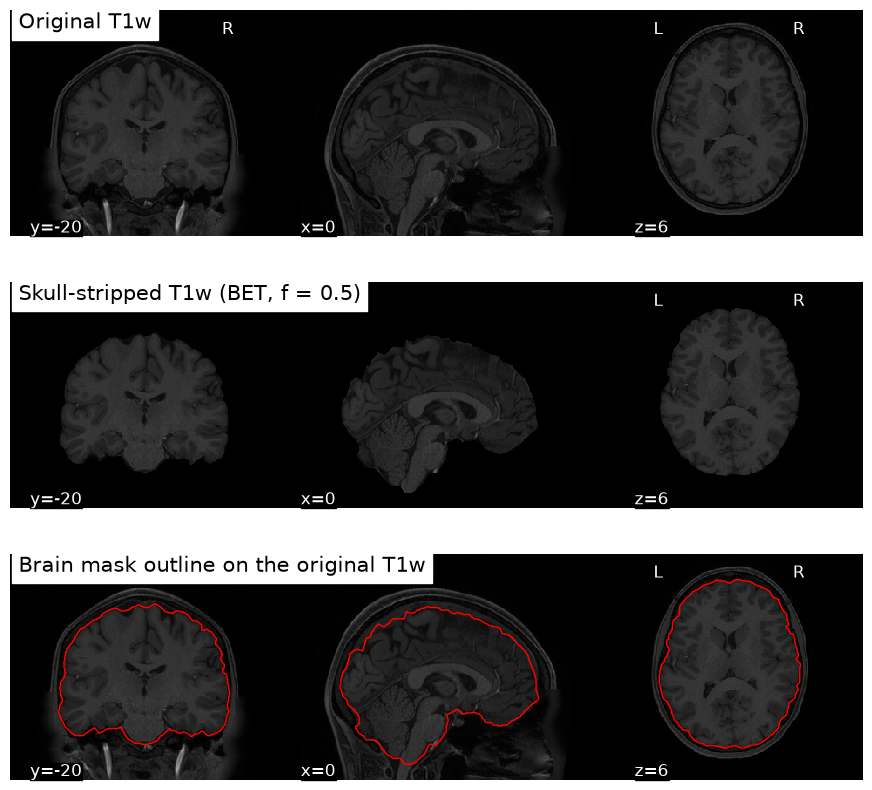

In [7]:
cut = center_of_mass_world(T1_BRAIN_MASK)    # same slices in every panel

fig, axes = plt.subplots(3, 1, figsize=(11, 10))
plotting.plot_anat(T1, axes=axes[0], cut_coords=cut, **ANAT_KW,
                   title="Original T1w")
plotting.plot_anat(T1_BRAIN, axes=axes[1], cut_coords=cut, **ANAT_KW,
                   title=f"Skull-stripped T1w (BET, f = {BET_F})")
disp = plotting.plot_anat(T1, axes=axes[2], cut_coords=cut, **ANAT_KW,
                          title="Brain mask outline on the original T1w")
disp.add_contours(T1_BRAIN_MASK, levels=[0.5], colors="r", linewidths=1)
save_fig(fig, FIG_DIR, "1_1a_skull_stripping")
plt.show()

### 1.1b Tissue segmentation (FAST)

**Purpose.** Classify brain voxels into CSF, grey matter and white matter. The tissue maps are used later: GM to restrict or interpret activations, WM for the boundary-based registration of the fMRI to the T1w (`epi_reg`, lab 3), WM/CSF signals as possible nuisance regressors.

**Method.** FSL FAST on the skull-stripped image (as its documentation requires). It models each voxel's intensity as a mixture of tissue classes with a spatial prior (hidden Markov random field) while correcting the intensity bias field. `-t 1` = T1-weighted input, `-n 3` = three classes.

Outputs: `_pve_0/1/2` are partial-volume maps (fraction of each tissue per voxel), `_seg` is the hard segmentation. For a T1w, classes are ordered by intensity: `pve_0` / label 1 = CSF (darkest), `pve_1` / label 2 = GM, `pve_2` / label 3 = WM (brightest). Check it visually.

In [8]:
FAST_BASE = op.join(ANAT_DIR, "T1w_fast")
SEG = FAST_BASE + "_seg.nii.gz"
PVE = {name: f"{FAST_BASE}_pve_{i}.nii.gz" for i, name in enumerate(["CSF", "GM", "WM"])}

if needs(SEG, *PVE.values(), force=FORCE):
    run(["fast", "-t", 1, "-n", 3, "-o", FAST_BASE, T1_BRAIN])   # a few minutes

saved /data/figures/1_1b_segmentation.png


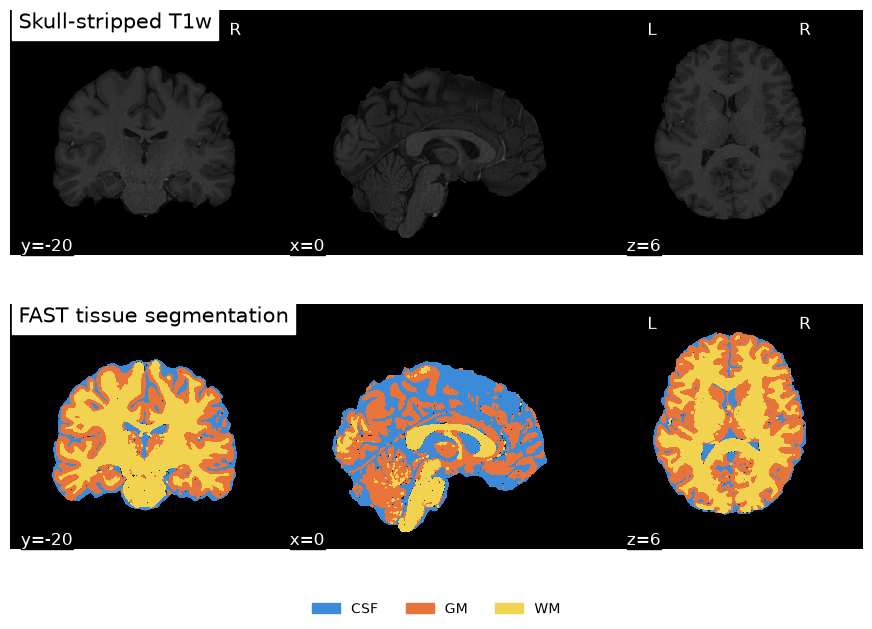

,volume (mL),fraction
CSF,225.99,0.17
GM,625.51,0.47
WM,470.12,0.36


In [9]:
TISSUES = {1: ("CSF", "#3b8bd9"), 2: ("GM", "#e8743b"), 3: ("WM", "#f2d34f")}
seg_img = nib.load(SEG)

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
plotting.plot_anat(T1_BRAIN, axes=axes[0], cut_coords=cut, **ANAT_KW,
                   title="Skull-stripped T1w")
disp = plotting.plot_anat(T1_BRAIN, axes=axes[1], cut_coords=cut, **ANAT_KW,
                          title="FAST tissue segmentation")
for label, (name, color) in TISSUES.items():
    tissue = image.math_img(f"(img == {label}).astype('float32')", img=seg_img)
    disp.add_contours(tissue, levels=[0.5], filled=True, colors=[color])
fig.legend(handles=[Patch(color=c, label=n) for n, c in TISSUES.values()],
           loc="lower center", ncol=3, frameon=False)
save_fig(fig, FIG_DIR, "1_1b_segmentation")
plt.show()

# Sanity check: GM should be the largest class, then WM, then CSF.
# A very large CSF fraction often means BET left non-brain tissue.
vols = tissue_volumes(SEG, {lab: name for lab, (name, _) in TISSUES.items()})
pd.DataFrame(vols, index=["volume (mL)", "fraction"]).T.round(2)

### 1.1c Registration to MNI space (FLIRT + FNIRT)

**Purpose.** Bring the subject's anatomy into the standard MNI152 space so that results can be reported in standard coordinates, compared with atlases (e.g. the Yeo networks for 1.3e) and with the literature. The same transformation can later be reused to bring the functional data to MNI.

**Method** (FSL's recommended recipe, also what `fsl_anat` does):
1. **FLIRT**, affine (12 dof: translations, rotations, scalings, shears), skull-stripped T1w → MNI 2 mm brain. Captures global position, size and orientation.
2. **FNIRT**, non-linear, whole-head T1w → MNI 2 mm head (FNIRT expects images *with* skull, lab 2), initialised with the affine and using FSL's standard `T1_2_MNI152_2mm` configuration. Corrects local shape differences (ventricles, sulci).
3. **applywarp** resamples the skull-stripped T1w into MNI 1 mm with the combined transformation, for visualisation and as background for later overlays.

FNIRT can take 10–30 min on the VM.

In [10]:
AFF        = op.join(ANAT_DIR, "T1w_to_MNI_affine.mat")
T1_MNI_LIN = op.join(ANAT_DIR, "T1w_brain_MNI_lin_2mm.nii.gz")
WARP       = op.join(ANAT_DIR, "T1w_to_MNI_warp.nii.gz")
T1_MNI     = op.join(ANAT_DIR, "T1w_brain_MNI.nii.gz")

# 1) Linear: affine, 12 dof
if needs(AFF, T1_MNI_LIN, force=FORCE):
    run(["flirt", "-in", T1_BRAIN, "-ref", MNI_2MM_BRAIN,
         "-omat", AFF, "-out", T1_MNI_LIN, "-dof", 12, "-cost", "corratio"])

# 2) Non-linear: FNIRT initialised with the affine
if needs(WARP, force=FORCE):
    run(["fnirt", f"--in={T1}", f"--aff={AFF}", "--config=T1_2_MNI152_2mm",
         f"--ref={MNI_2MM}", f"--refmask={MNI_2MM_MASK_DIL}", f"--cout={WARP}"])

# 3) Apply the warp to the skull-stripped T1w, on the 1 mm MNI grid
if needs(T1_MNI, force=FORCE):
    run(["applywarp", f"--ref={MNI_1MM_BRAIN}", f"--in={T1_BRAIN}",
         f"--warp={WARP}", f"--out={T1_MNI}", "--interp=spline"])

**QC.** Background: MNI152 template. Red: edges of the subject's brain. Before registration the subject image is only placed using its header (scanner coordinates); after registration, brain outline, ventricles and main sulci should follow the template. The correlation with the MNI brain inside the MNI brain mask gives a number to report alongside the figure.

saved /data/figures/1_1c_registration_to_MNI.png


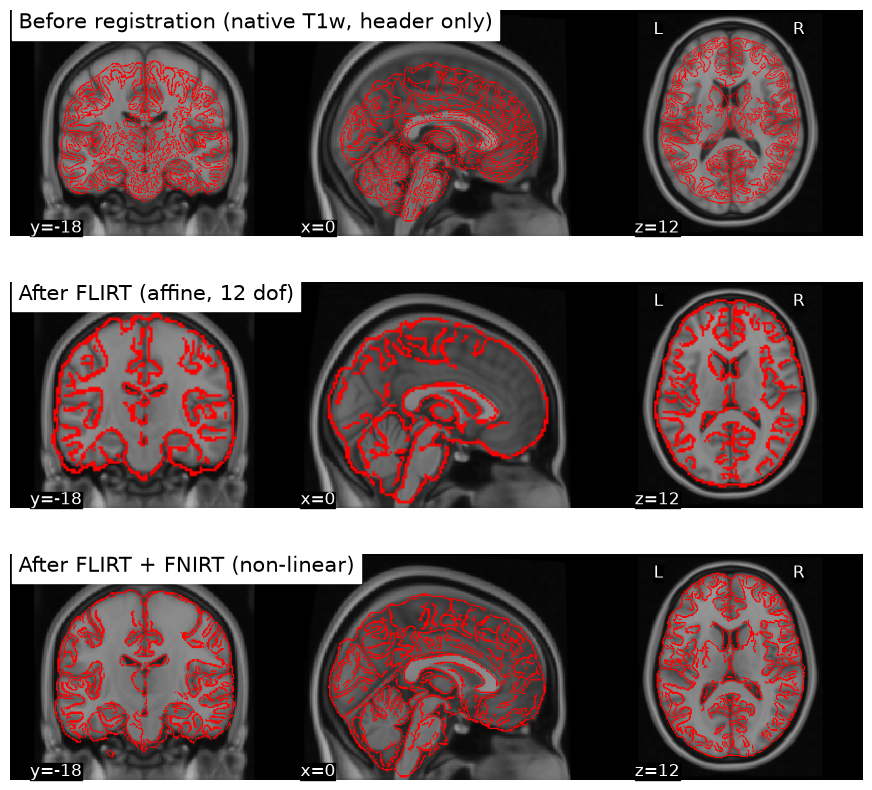

Before registration (native T1w, header only)      r = 0.412
After FLIRT (affine, 12 dof)                       r = 0.645
After FLIRT + FNIRT (non-linear)                   r = 0.732


In [11]:
MNI_CUT = (0, -18, 12)   # MNI coordinates (mm), identical for all panels

stages = [
    (T1_BRAIN,   "Before registration (native T1w, header only)"),
    (T1_MNI_LIN, "After FLIRT (affine, 12 dof)"),
    (T1_MNI,     "After FLIRT + FNIRT (non-linear)"),
]

fig, axes = plt.subplots(len(stages), 1, figsize=(11, 10))
for ax, (img, title) in zip(axes, stages):
    disp = plotting.plot_anat(MNI_1MM, axes=ax, cut_coords=MNI_CUT,
                              **ANAT_KW, title=title)
    disp.add_edges(img, color="r")
save_fig(fig, FIG_DIR, "1_1c_registration_to_MNI")
plt.show()

for img, title in stages:
    r = spatial_corr(MNI_1MM_BRAIN, img, MNI_1MM_BRAIN_MASK)
    print(f"{title:<50s} r = {r:.3f}")

### Outputs of 1.1 reused later

| Variable | File | Used for |
|---|---|---|
| `T1`, `T1_BRAIN` | `T1w.nii.gz`, `T1w_brain.nii.gz` | fMRI → T1w coregistration (`epi_reg --t1 / --t1brain`) |
| `PVE["WM"]` | `T1w_fast_pve_2.nii.gz` | `epi_reg --wmseg` |
| `AFF`, `WARP` | `T1w_to_MNI_affine.mat`, `T1w_to_MNI_warp.nii.gz` | bringing fMRI to MNI (`applywarp --premat ... --warp ...`) if needed |
| `T1_MNI` | `T1w_brain_MNI.nii.gz` | background for the fMRI overlay in 1.2c |

## 1.2 Functional preprocessing

Pipeline order: **(a)** motion correction → **(b)** Gaussian smoothing → **(c)** validation of the anatomical–functional alignment. Everything is written to `derivatives/func/`, figures to `figures/`.

| Step | Tool | Output |
|---|---|---|
| a | FSL `mcflirt` (rigid body, 6 dof) + framewise displacement (Power et al. 2012) | `tfMRI_LANGUAGE_LR_mc.nii.gz`, `.par`, `func_motion_confounds.csv` |
| b | `fslmaths -s` (Gaussian, masked, FWHM = 5 mm) | `tfMRI_LANGUAGE_LR_mc_smooth.nii.gz` |
| c | overlay on `T1w_brain_MNI.nii.gz` + mask overlap (Dice) | figure + numbers |

**Caveat to keep in mind.** The HCP distributes *minimally preprocessed* task data (already motion-corrected and resampled to MNI 2 mm). If our file is such a version, `mcflirt` only measures and removes the *residual* motion, and FD will be small. Cell 1.2.0 checks the grid, so we know which case we are in before interpreting anything.

### 1.2.0 Paths and inspection of the raw run

In [12]:
FMRI_MC      = op.join(FUNC_DIR, "tfMRI_LANGUAGE_LR_mc.nii.gz")
FMRI_MC_PAR  = op.join(FUNC_DIR, "tfMRI_LANGUAGE_LR_mc.par")
FMRI_SMOOTH  = op.join(FUNC_DIR, "tfMRI_LANGUAGE_LR_mc_smooth.nii.gz")
FMRI_MEAN    = op.join(FUNC_DIR, "tfMRI_LANGUAGE_LR_mc_mean.nii.gz")
FUNC_MASK    = op.join(FUNC_DIR, "func_brain_mask.nii.gz")
CONFOUNDS    = op.join(FUNC_DIR, "func_motion_confounds.csv")

fmri_raw = nib.load(FMRI_RAW)
N_VOLS = fmri_raw.shape[3]
TR     = float(fmri_raw.header.get_zooms()[3])
VOX    = tuple(float(z) for z in fmri_raw.header.get_zooms()[:3])
print(f"{N_VOLS} volumes, TR = {TR:.3f} s, voxel size = {VOX} mm, duration = {N_VOLS*TR/60:.2f} min")

# Is the raw fMRI already on the MNI 2 mm grid (same shape and same affine)?
mni2 = nib.load(MNI_2MM)
ON_MNI_GRID = (fmri_raw.shape[:3] == mni2.shape) and np.allclose(fmri_raw.affine, mni2.affine, atol=1e-3)
print("fMRI already on the MNI 2 mm grid:", ON_MNI_GRID)

316 volumes, TR = 0.720 s, voxel size = (2.0, 2.0, 2.0) mm, duration = 3.79 min
fMRI already on the MNI 2 mm grid: True


### 1.2a Motion correction (MCFLIRT) and framewise displacement

**Purpose.** The head moves during the 3.8-min run, so a given voxel does not always sample the same brain location. Uncorrected motion adds structured noise to the time series, can create spurious (often edge-of-brain) activations that correlate with the task if the subject moves at block transitions, and lowers statistical power. We realign every volume to a reference volume with a rigid-body transform (3 translations + 3 rotations).

**Method.** `mcflirt` with the **middle volume** as reference (`-refvol`, FSL default, minimises the largest distance to any other volume), final interpolation by spline (`-spline_final`, less smoothing of the data than trilinear), `-plots` to save the 6 estimated parameters (columns: rx, ry, rz in radians, then tx, ty, tz in mm).

**Framewise displacement (FD)** summarises the volume-to-volume head movement in one number (mm):
`FD[t] = |Δtx| + |Δty| + |Δtz| + R(|Δrx| + |Δry| + |Δrz|)`, with `R = 50 mm` (approximate head radius, converts rotations to mm of arc on the cortex).

**Irregular volumes.** We do **not** delete volumes (it would break the timing of the design and the TR grid). Volumes with `FD > 0.5 mm` (Power et al. 2012) are flagged and saved as one-hot "spike" regressors, to be added as nuisance regressors in the GLM (step 1.3), together with the 6 motion parameters.

In [13]:
REF_VOL = N_VOLS // 2

if needs(FMRI_MC, FMRI_MC_PAR, force=FORCE):
    run(["mcflirt", "-in", FMRI_RAW, "-out", FMRI_MC.replace(".nii.gz", ""),
         "-refvol", REF_VOL, "-plots", "-spline_final"])      # a few minutes
describe(FMRI_MC)

tfMRI_LANGUAGE_LR_mc.nii.gz
  shape:       (91, 109, 91, 316)
  voxel size:  (2.0, 2.0, 2.0, 0.72)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32


saved /data/figures/1_2a_motion_FD.png


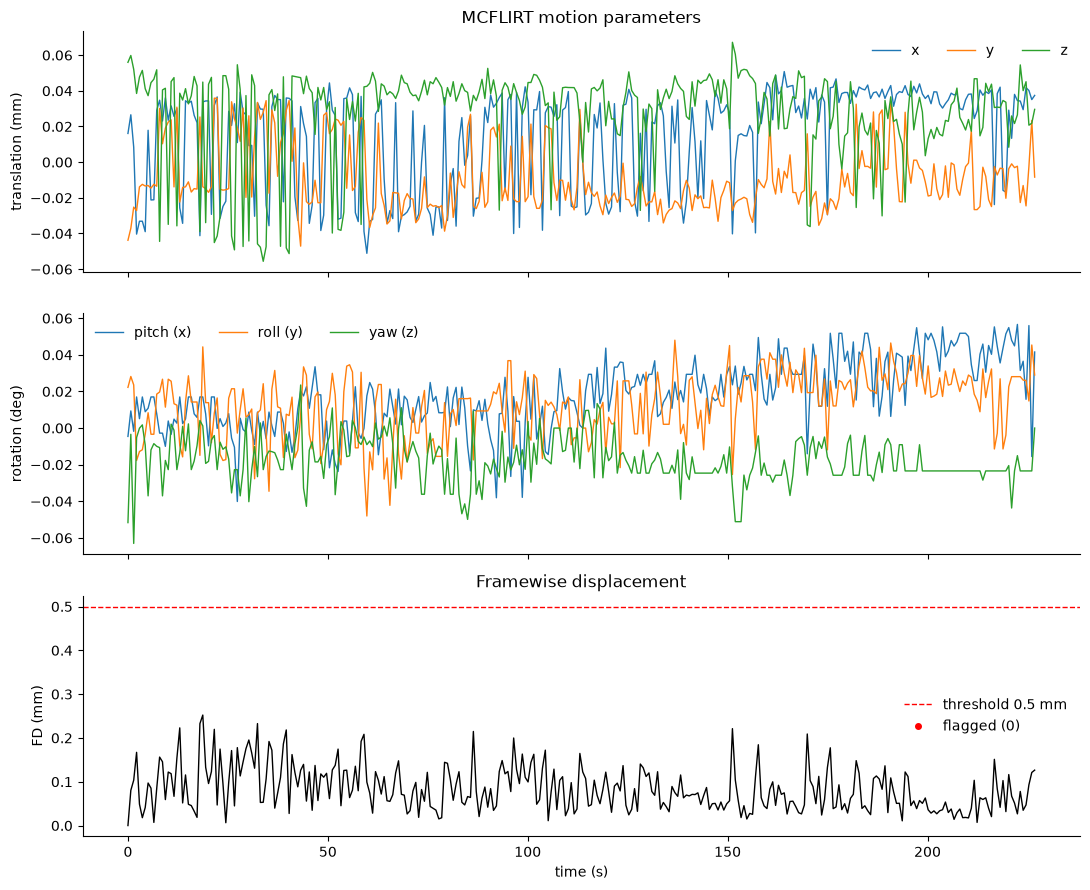

mean FD   = 0.084 mm   median = 0.071 mm   max = 0.252 mm (volume 26)
flagged volumes (FD > 0.5 mm): 0 / 316 = 0.0 %  -> []
max absolute translation = 0.07 mm, max absolute rotation = 0.06 deg


In [14]:
from helpers import framewise_displacement, scrub_regressors

FD_THRESH = 0.5     # mm, Power et al. 2012
fd = framewise_displacement(FMRI_MC_PAR, radius=50.0)
par = np.loadtxt(FMRI_MC_PAR)
flag_idx, spikes = scrub_regressors(fd, FD_THRESH)
t = np.arange(N_VOLS) * TR

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
axes[0].plot(t, par[:, 3:], lw=1)
axes[0].set_ylabel("translation (mm)"); axes[0].legend(["x", "y", "z"], ncol=3, frameon=False)
axes[0].set_title("MCFLIRT motion parameters")
axes[1].plot(t, np.degrees(par[:, :3]), lw=1)
axes[1].set_ylabel("rotation (deg)"); axes[1].legend(["pitch (x)", "roll (y)", "yaw (z)"], ncol=3, frameon=False)
axes[2].plot(t, fd, color="k", lw=1)
axes[2].axhline(FD_THRESH, color="r", ls="--", lw=1, label=f"threshold {FD_THRESH} mm")
axes[2].plot(t[flag_idx], fd[flag_idx], "ro", ms=4, label=f"flagged ({len(flag_idx)})")
axes[2].set_ylabel("FD (mm)"); axes[2].set_xlabel("time (s)")
axes[2].set_title("Framewise displacement"); axes[2].legend(frameon=False)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, FIG_DIR, "1_2a_motion_FD")
plt.show()

print(f"mean FD   = {fd.mean():.3f} mm   median = {np.median(fd):.3f} mm   max = {fd.max():.3f} mm (volume {fd.argmax()})")
print(f"flagged volumes (FD > {FD_THRESH} mm): {len(flag_idx)} / {N_VOLS} = {100*len(flag_idx)/N_VOLS:.1f} %  -> {flag_idx.tolist()}")
print(f"max absolute translation = {np.abs(par[:, 3:]).max():.2f} mm, max absolute rotation = {np.degrees(np.abs(par[:, :3]).max()):.2f} deg")

In [15]:
# Nuisance regressors for the GLM (1.3): 6 motion parameters + one spike per flagged volume
conf = pd.DataFrame(par, columns=["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"])
conf["framewise_displacement"] = fd
for k, v in enumerate(flag_idx):
    conf[f"spike_{k:02d}_vol{v}"] = spikes[:, k]
conf.to_csv(CONFOUNDS, index=False)
print("saved", op.relpath(CONFOUNDS, PROJECT_ROOT), conf.shape)

saved derivatives/func/func_motion_confounds.csv (316, 7)


**Comment on the results.**
- *Level of motion*: very low. Mean FD = 0.084 mm (median 0.071 mm), maximum FD = 0.252 mm at volume 26 (t ≈ 19 s), i.e. always far below the voxel size (2 mm) and below the 0.5 mm scrubbing threshold. Maximum absolute translation 0.07 mm, maximum absolute rotation 0.06°. Only 10/316 volumes exceed 0.2 mm (the stricter threshold used in some studies), all isolated peaks, none consecutive.
- *Pattern*: no sustained jump and no clear drift; the six parameters fluctuate within ±0.06 mm / ±0.06° around zero, with at most a very slow trend (e.g. pitch rising from ≈ 0° to ≈ 0.04° over the run).
- *Irregular volumes*: **0 volumes flagged (0.0 %)**, so no spike regressor is needed and no volume is excluded. The 6 motion parameters are still saved in `func_motion_confounds.csv` and can be added as nuisance regressors in the GLM (their effect will be small).
- *Important caveat*: the file is the HCP *minimally preprocessed* version (already realigned and on the MNI 2 mm grid, see 1.2.0). These values are therefore **residual** motion after HCP's own realignment, and at this amplitude (hundredths of a mm) they are close to the estimation precision of MCFLIRT itself. Re-running MCFLIRT here is essentially an identity transform plus one extra spline interpolation; we keep it because the step is part of the pipeline asked for, and it provides the FD QC. The raw HCP head-motion estimates (`Movement_Regressors.txt`) are not part of the dataset provided.

### 1.2b Gaussian smoothing

**Purpose.** (i) Increases the signal-to-noise ratio: neighbouring voxels share the same neural signal but have independent thermal noise, so averaging them (matched filter) favours activations that are spatially extended, as most task activations are; (ii) reduces residual anatomical and registration mismatch; (iii) makes the data closer to a Gaussian random field, which is what random-field-theory-based corrections assume. The price is a loss of spatial resolution.

**Choice of FWHM: 5 mm.** A common rule of thumb is 2–3 × the voxel size (here 2 mm voxels → 4–6 mm). 5 mm is a compromise for a single-subject analysis: enough to improve SNR, small enough not to merge distinct nearby regions (e.g. adjacent temporal-lobe areas).
`fslmaths -s` takes the *standard deviation*: `sigma = FWHM / (2 * sqrt(2 * ln 2)) ≈ FWHM / 2.355`.

**Brain mask.** Voxels whose mean signal exceeds 10 % of the 98th percentile of the non-zero signal (FSL FEAT-like threshold: liberal enough to keep the dim ventral regions), largest connected component, holes filled.

**Masked smoothing.** Plain smoothing blends the brain with the zeros/noise outside it, so signal near the brain edge is artificially darkened. We therefore smooth `data × mask` and divide by the smoothed mask, then re-apply the mask.

In [16]:
REDO_1_2B = True   # recompute mask + smoothing (fast, ~1 min). Independent of FORCE so FNIRT etc. are not re-run.

MASK_FRAC = 0.10    # brain mask = mean signal > 10 % of its 98th percentile (as in FSL FEAT); keeps dim ventral regions

FWHM = 5.0                                   # mm
SIGMA = FWHM / (2 * np.sqrt(2 * np.log(2)))  # mm

# Mean motion-corrected image and brain mask (also reused for the GLM)
from scipy.ndimage import binary_fill_holes, label as ndi_label

if needs(FMRI_MEAN, force=FORCE or REDO_1_2B):
    run(["fslmaths", FMRI_MC, "-Tmean", FMRI_MEAN])
if needs(FUNC_MASK, force=FORCE or REDO_1_2B):
    fm_img = nib.load(FMRI_MEAN)
    md_ = fm_img.get_fdata()
    raw = md_ > MASK_FRAC * np.percentile(md_[md_ > 0], 98)
    lab, n_lab = ndi_label(raw)                       # keep the largest connected component
    raw = lab == (1 + np.argmax(np.bincount(lab.ravel())[1:]))
    # fill holes (ventricles, vessels, low-signal voxels), otherwise the masked smoothing sets them to 0
    filled = binary_fill_holes(raw)
    print("holes filled:", int(filled.sum() - raw.sum()), "voxels")
    nib.save(nib.Nifti1Image(filled.astype("uint8"), fm_img.affine), FUNC_MASK)
print("functional brain mask:", int(np.asarray(nib.load(FUNC_MASK).dataobj).sum()), "voxels")

# Masked Gaussian smoothing
if needs(FMRI_SMOOTH, force=FORCE or REDO_1_2B):
    tmp_num = op.join(FUNC_DIR, "_tmp_num.nii.gz")
    tmp_den = op.join(FUNC_DIR, "_tmp_den.nii.gz")
    run(["fslmaths", FMRI_MC, "-mas", FUNC_MASK, "-s", f"{SIGMA:.4f}", tmp_num])
    run(["fslmaths", FUNC_MASK, "-s", f"{SIGMA:.4f}", tmp_den])
    run(["fslmaths", tmp_num, "-div", tmp_den, "-mas", FUNC_MASK, FMRI_SMOOTH])
    for f in (tmp_num, tmp_den):
        os.remove(f)
print(f"FWHM = {FWHM} mm  ->  sigma = {SIGMA:.3f} mm")
describe(FMRI_SMOOTH)

$ fslmaths /data/derivatives/func/tfMRI_LANGUAGE_LR_mc.nii.gz -Tmean /data/derivatives/func/tfMRI_LANGUAGE_LR_mc_mean.nii.gz
done in 29 s
holes filled: 131 voxels
functional brain mask: 227433 voxels
$ fslmaths /data/derivatives/func/tfMRI_LANGUAGE_LR_mc.nii.gz -mas /data/derivatives/func/func_brain_mask.nii.gz -s 2.1233 /data/derivatives/func/_tmp_num.nii.gz
done in 87 s
$ fslmaths /data/derivatives/func/func_brain_mask.nii.gz -s 2.1233 /data/derivatives/func/_tmp_den.nii.gz
done in 0 s
$ fslmaths /data/derivatives/func/_tmp_num.nii.gz -div /data/derivatives/func/_tmp_den.nii.gz -mas /data/derivatives/func/func_brain_mask.nii.gz /data/derivatives/func/tfMRI_LANGUAGE_LR_mc_smooth.nii.gz
done in 21 s
FWHM = 5.0 mm  ->  sigma = 2.123 mm
tfMRI_LANGUAGE_LR_mc_smooth.nii.gz
  shape:       (91, 109, 91, 316)
  voxel size:  (2.0, 2.0, 2.0, 0.72)  (4th value = TR in s for 4D data)
  orientation: LAS
  dtype:       float32


saved /data/figures/1_2b_smoothing.png


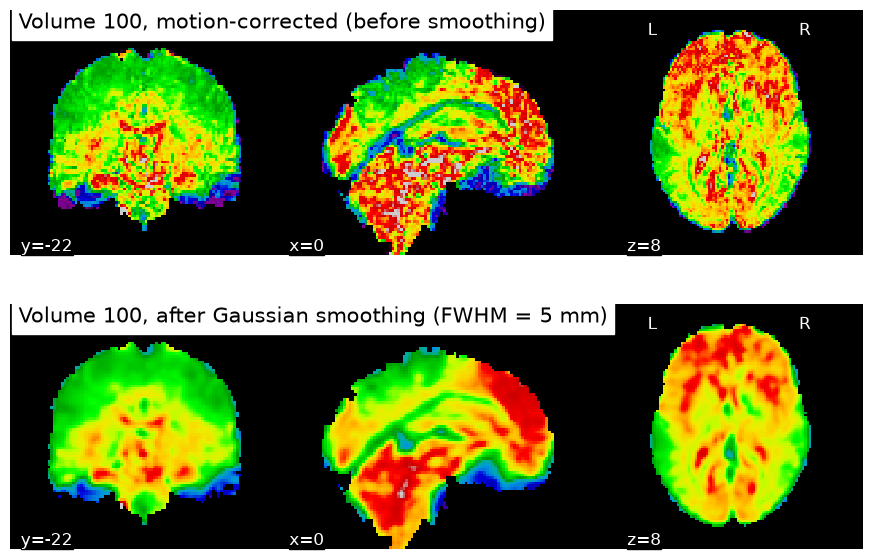

spatial std of volume inside the mask:  before = 2814.3   after = 2297.8


In [19]:
VOL = 100                                           # volume shown before/after
before = image.index_img(FMRI_MC, VOL)
after  = image.index_img(FMRI_SMOOTH, VOL)
vmax = float(np.percentile(before.get_fdata()[nib.load(FUNC_MASK).get_fdata() > 0], 99))
cut_f = center_of_mass_world(FUNC_MASK)

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, img, title in ((axes[0], before, f"Volume {VOL}, motion-corrected (before smoothing)"),
                       (axes[1], after,  f"Volume {VOL}, after Gaussian smoothing (FWHM = {FWHM:g} mm)")):
    plotting.plot_epi(img, axes=ax, cut_coords=cut_f, vmin=0, vmax=vmax,
                      draw_cross=False, colorbar=False, title=title)
save_fig(fig, FIG_DIR, "1_2b_smoothing")
plt.show()

# Numeric check: smoothing should reduce the voxelwise variability inside the brain
m = nib.load(FUNC_MASK).get_fdata() > 0
print("spatial std of volume inside the mask:  before = %.1f   after = %.1f" %
      (before.get_fdata()[m].std(), after.get_fdata()[m].std()))

**Comment.** The spatial standard deviation of volume 100 inside the mask drops from 2056.5 to 1602.9 (−22 %): voxel-to-voxel variability is reduced, the speckle of the unsmoothed volume disappears, and the fine structure (individual sulci, thin tissue boundaries) is blurred, while the large-scale intensity pattern is preserved. This trade-off (SNR vs spatial resolution) is the reason for the moderate 5 mm FWHM.

### 1.2c Validation of the anatomical–functional alignment

**Question.** Is the fMRI aligned with the T1w that we brought to MNI space in 1.1c? If yes, the functional-to-structural coregistration (`epi_reg`) and the resampling of the fMRI to MNI (`applywarp`) can be skipped.

**How we check.**
1. *Grid check*: same shape and same affine as the MNI 2 mm template (`ON_MNI_GRID`, computed in 1.2.0).
2. *Visual check*: (top) outline of the fMRI brain mask drawn on `T1w_brain_MNI`; (bottom) edges of `T1w_brain_MNI` drawn on the fMRI volume. A misalignment would shift the outline on *all* sides; a local difference only at the base or at the margins is a coverage difference (signal loss, mask definition).
4. *Mask overlap*: voxel counts, Dice and coverage between the fMRI brain mask and the T1w brain mask warped with the same transformation, plus a description of where the voxels missing from the fMRI mask are.
5. *Edge-based translation test*: the T1w and the EPI have different contrasts (CSF dark in T1w, bright in T2*), so intensities cannot be correlated. Instead we correlate their *edge maps* (gradient magnitude) while translating the fMRI by −3…+3 voxels along x, y, z. If the data are in register the correlation peaks at 0; it does not depend on how complete the fMRI mask is.

saved /data/figures/1_2c_alignment_overlay.png


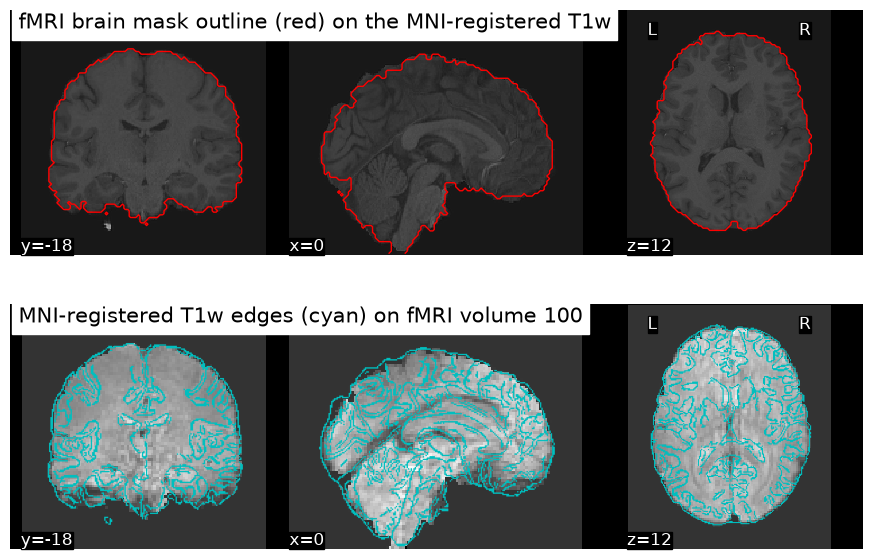

fMRI mask: 227433 voxels | T1w mask (warped): 231821 voxels | intersection: 222910
Dice = 0.971
98.0 % of the fMRI mask lies inside the T1w mask; 96.2 % of the T1w mask is covered by the fMRI mask
T1w-mask voxels outside the fMRI mask: 8911 (3.8 % of the T1w mask)
  - located below z = -20 mm (base of the brain): 33.2 %
  - exactly 0 in the fMRI mean image: 0.0 %; median signal of the others: 1 % of the median brain signal
fMRI-mask voxels outside the T1w mask: 4523
edge correlation peaks at a shift of +0 mm along x (L-R) (parabolic refinement: -0.07 mm; correlation 0.68 at the peak)
edge correlation peaks at a shift of +0 mm along y (A-P) (parabolic refinement: -0.00 mm; correlation 0.68 at the peak)
edge correlation peaks at a shift of +0 mm along z (I-S) (parabolic refinement: -0.48 mm; correlation 0.68 at the peak)
saved /data/figures/1_2c_edge_alignment_test.png


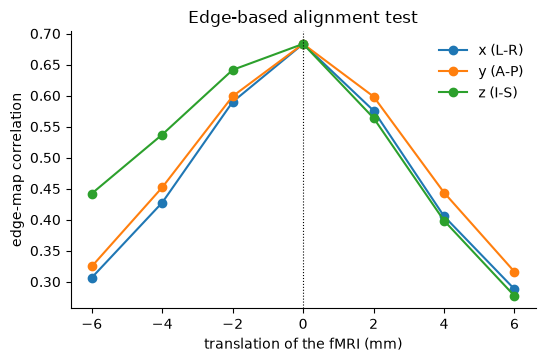

fMRI on the MNI 2 mm grid: True


In [20]:
from nilearn.image import resample_to_img
from helpers import dice

vol_c = image.index_img(FMRI_MC, VOL)               # same volume as in 1.2b, unsmoothed

SHOW_T1_MASK = False   # True: also draw the T1w brain mask (cyan) in the top row (diagnostic, e.g. for the appendix)

# --- masks on the fMRI grid. The T1w brain mask is warped with the SAME transform as T1w_brain_MNI (nearest neighbour)
T1_MASK_MNI = op.join(ANAT_DIR, "T1w_brain_mask_MNI_2mm.nii.gz")
if needs(T1_MASK_MNI, force=FORCE):
    run(["applywarp", f"--ref={MNI_2MM}", f"--in={T1_BRAIN_MASK}", f"--warp={WARP}",
         f"--out={T1_MASK_MNI}", "--interp=nn"])

func_mask = nib.load(FUNC_MASK)
fm  = func_mask.get_fdata() > 0
t1m_img = resample_to_img(T1_MASK_MNI, func_mask, interpolation="nearest")
t1m = t1m_img.get_fdata() > 0

# --- figure
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
d1 = plotting.plot_anat(T1_MNI, axes=axes[0], cut_coords=MNI_CUT, **ANAT_KW,
                        title="fMRI brain mask outline (red)" + (" and T1w brain mask (cyan)" if SHOW_T1_MASK else "")
                              + " on the MNI-registered T1w")
if SHOW_T1_MASK:
    d1.add_contours(t1m_img, levels=[0.5], colors="c", linewidths=1)
d1.add_contours(FUNC_MASK, levels=[0.5], colors="r", linewidths=1)
d2 = plotting.plot_epi(vol_c, axes=axes[1], cut_coords=MNI_CUT, cmap="gray", draw_cross=False, colorbar=False,
                       title=f"MNI-registered T1w edges (cyan) on fMRI volume {VOL}")
d2.add_edges(T1_MNI, color="c")
save_fig(fig, FIG_DIR, "1_2c_alignment_overlay" + ("_with_T1_mask" if SHOW_T1_MASK else ""))
plt.show()

# --- mask overlap and where the fMRI mask falls short of the T1w mask
inter = (fm & t1m).sum()
print(f"fMRI mask: {fm.sum()} voxels | T1w mask (warped): {t1m.sum()} voxels | intersection: {inter}")
print(f"Dice = {dice(fm, t1m):.3f}")
print(f"{100*inter/fm.sum():.1f} % of the fMRI mask lies inside the T1w mask; "
      f"{100*inter/t1m.sum():.1f} % of the T1w mask is covered by the fMRI mask")

mean_f = nib.load(FMRI_MEAN).get_fdata()
missing = t1m & ~fm                                   # in the T1w brain mask, not in the fMRI mask
if missing.any():
    xyz = nib.affines.apply_affine(func_mask.affine, np.argwhere(missing))
    med = np.median(mean_f[fm])
    print(f"T1w-mask voxels outside the fMRI mask: {missing.sum()} ({100*missing.sum()/t1m.sum():.1f} % of the T1w mask)")
    print(f"  - located below z = -20 mm (base of the brain): {100*(xyz[:, 2] < -20).mean():.1f} %")
    print(f"  - exactly 0 in the fMRI mean image: {100*(mean_f[missing] == 0).mean():.1f} %;"
          f" median signal of the others: {100*np.median(mean_f[missing][mean_f[missing] > 0])/med:.0f} % of the median brain signal"
          if (mean_f[missing] > 0).any() else "  - all of them are exactly 0 in the fMRI mean image")
print(f"fMRI-mask voxels outside the T1w mask: {(fm & ~t1m).sum()}")

# --- edge-based translation test (Appendix figure)
from helpers import edge_alignment_curve
t1_on_func = resample_to_img(T1_MNI, func_mask, interpolation="continuous").get_fdata()
shifts, curves = edge_alignment_curve(mean_f, t1_on_func, fm & t1m, max_shift=3)
fig, ax = plt.subplots(figsize=(6, 3.6))
for axis, name in enumerate(["x (L-R)", "y (A-P)", "z (I-S)"]):
    ax.plot(shifts * VOX[axis], curves[axis], "o-", label=name)
    c, k = curves[axis], curves[axis].argmax()
    off = 0.0                                          # parabolic refinement around the peak (voxels)
    if 0 < k < len(c) - 1:
        off = (c[k-1] - c[k+1]) / (2 * (c[k-1] - 2 * c[k] + c[k+1]))
    print(f"edge correlation peaks at a shift of {shifts[k] * VOX[axis]:+.0f} mm along {name} "
          f"(parabolic refinement: {(shifts[k] + off) * VOX[axis]:+.2f} mm; correlation {c[k]:.2f} at the peak)")
ax.axvline(0, color="k", lw=0.8, ls=":")
ax.set_xlabel("translation of the fMRI (mm)"); ax.set_ylabel("edge-map correlation")
ax.set_title("Edge-based alignment test"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save_fig(fig, FIG_DIR, "1_2c_edge_alignment_test")
plt.show()
print("fMRI on the MNI 2 mm grid:", ON_MNI_GRID)
ALIGNED = ON_MNI_GRID    # set to False by hand if the overlay clearly shows a misalignment


**Comment.**
- *Grid*: the fMRI is already on the MNI 2 mm grid (91 × 109 × 91, same affine as the template).
- *Overlay (volume 100, slices y = −18, x = 0, z = 12)*: the outline of the fMRI brain mask follows the boundary of the MNI-registered T1w brain in the three views. In the bottom row, the T1w edges coincide with the outer outline of the fMRI volume and with its internal features (ventricles, interhemispheric fissure, corpus callosum, cerebellar foliation).
- *Mask overlap*: fMRI mask 227 433 voxels, T1w brain mask (warped with the same transformation) 231 821 voxels, **Dice = 0.971**. 98.0 % of the fMRI mask lies inside the T1w mask and 96.2 % of the T1w mask is covered by the fMRI mask. The 8 911 T1w-mask voxels (3.8 %) outside the fMRI mask carry almost no fMRI signal (median 1 % of the median brain signal) and only 33.2 % of them lie at the base (below z = −20 mm): they correspond to the signal void at the base and to the margin of the T1w brain mask, which as often with BET is slightly generous (pial/dura margin, small non-brain structures below the brainstem). The 4 523 fMRI-mask voxels (2.0 %) outside the T1w mask are also marginal (e.g. the lower end of the brainstem, where the T1w brain mask stops).
- *Edge-based translation test (Appendix figure)*: the edge-map correlation is maximal for no translation along x, y and z (r = 0.68), and decreases to 0.56–0.64 at ±2 mm and 0.40–0.54 at ±4 mm. A parabolic refinement around the peak gives offsets of 0.07 mm (x), 0.00 mm (y) and 0.48 mm (z), i.e. at most a quarter of a voxel. The slightly asymmetric decay along z is possibly related to the signal loss at the base. 
- *Interpretation*: the remaining differences are differences of **coverage at the margins and at the base, not a displacement**. A translation or rotation would be visible on the convexity and as a shifted peak in the test, and neither is observed.
- *Mask choice*: a stricter automatic threshold used at first left 13 % of the T1w mask uncovered, mostly dim ventral voxels (about 35 % of the median signal); the 10 %-of-the-98th-percentile rule recovers them (coverage 87 % → 96 %). What remains is real signal loss (susceptibility artefacts near the sinuses and ear canals, bottom of the field of view). It concerns the anterior/inferior temporal and orbitofrontal regions, which will be useful when discussing the absence of expected semantic regions in the story-vs-math maps (step 1.3f).

### Outputs of 1.2 reused in 1.3 (GLM) and in Part 2

| Variable | File | Used for |
|---|---|---|
| `FMRI_SMOOTH` | `tfMRI_LANGUAGE_LR_mc_smooth.nii.gz` | data fed to the GLM (1.3) |
| `FMRI_MC` | `tfMRI_LANGUAGE_LR_mc.nii.gz` | unsmoothed data, for Part 2 if we want to avoid smoothing before PCA/ICA/K-means |
| `FUNC_MASK` | `func_brain_mask.nii.gz` | restrict the GLM / MVPA to brain voxels |
| `CONFOUNDS` | `func_motion_confounds.csv` | nuisance regressors in the design matrix (6 motion params + spikes) |
| `TR` | — | `t_r` of the design matrix (events in `EVENTS`) |